BREAST CANCER PREDICTION USING LOGISTIC REGRESSION
A machine learning project to classify tumors as Benign or Malignant using the python embedded dataset called wisconsine


Importing python Libraries

In [26]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns

Loading the dataset to be used in the project

In [27]:
maindata = load_breast_cancer()

Splitting the dataset into python dataframe

In [28]:
df = pd.DataFrame(maindata.data, columns=maindata.feature_names)

Exploratory Data Analysis
This process is to inspect,examine and understand the data

In [29]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [30]:
df.shape

(569, 30)

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [32]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


Checking and handling missing values

In [33]:
df.isnull().sum()

,0
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Data Visualization

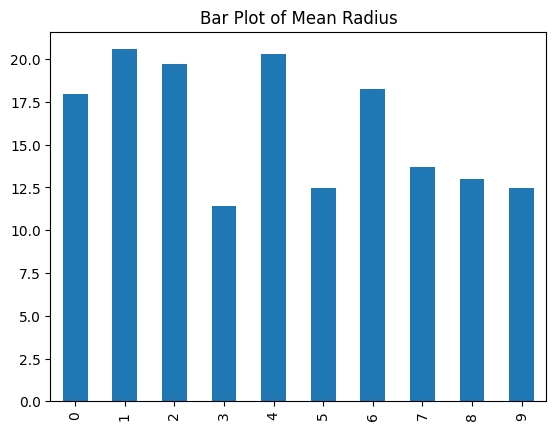

In [34]:
import matplotlib.pyplot as plt

#  Bar plot of Mean Radius
df['mean radius'].head(10).plot(kind='bar')
plt.title('Bar Plot of Mean Radius')
plt.show()


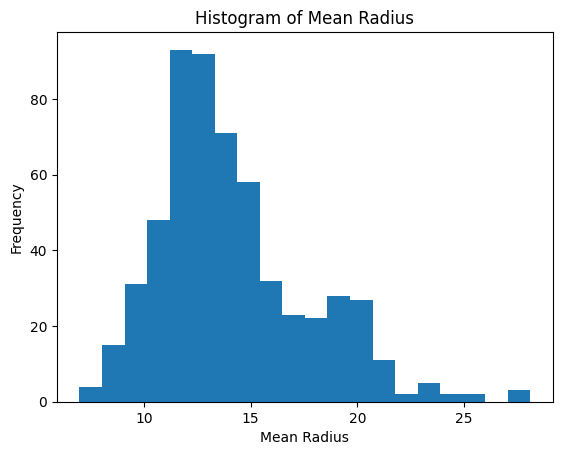

In [35]:
# Histogram of Mean Radius
plt.hist(df['mean radius'], bins=20)
plt.title('Histogram of Mean Radius')
plt.xlabel('Mean Radius')
plt.ylabel('Frequency')
plt.show()

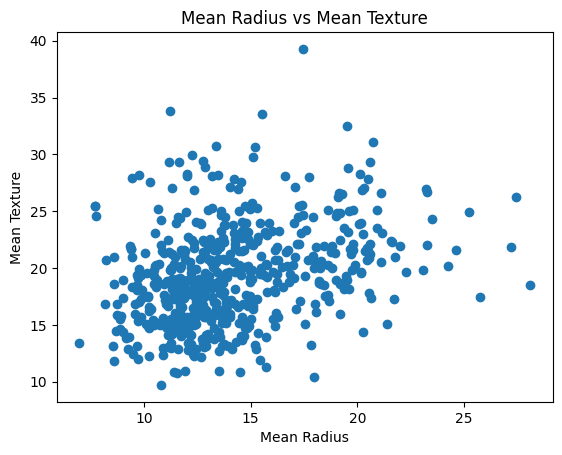

In [36]:
# Scatter plot of Mean Radius vs Mean Texture
plt.scatter(df['mean radius'], df['mean texture'])
plt.title('Mean Radius vs Mean Texture')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.show()

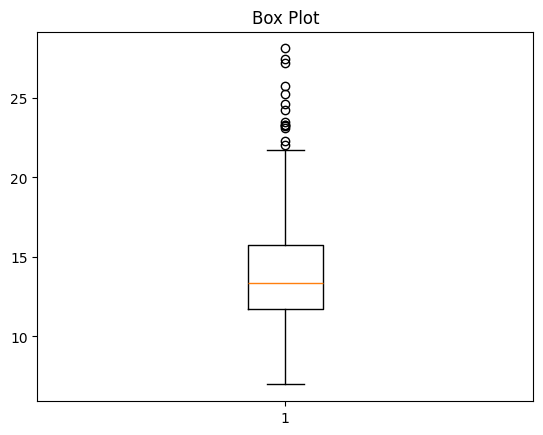

In [37]:
# Box plot of Mean Radius
plt.boxplot(df['mean radius'])
plt.title('Box Plot')
plt.show()

Feature Engineering

In [38]:
# Check potential outliers in all numerical columns

for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = df[(df[col] < Q1 - 1.5 * IQR) |
                  (df[col] > Q3 + 1.5 * IQR)]

    print(col, ":", len(outliers), "potential outliers")

mean radius : 14 potential outliers
mean texture : 7 potential outliers
mean perimeter : 13 potential outliers
mean area : 25 potential outliers
mean smoothness : 6 potential outliers
mean compactness : 16 potential outliers
mean concavity : 18 potential outliers
mean concave points : 10 potential outliers
mean symmetry : 15 potential outliers
mean fractal dimension : 15 potential outliers
radius error : 38 potential outliers
texture error : 20 potential outliers
perimeter error : 38 potential outliers
area error : 65 potential outliers
smoothness error : 30 potential outliers
compactness error : 28 potential outliers
concavity error : 22 potential outliers
concave points error : 19 potential outliers
symmetry error : 27 potential outliers
fractal dimension error : 28 potential outliers
worst radius : 17 potential outliers
worst texture : 5 potential outliers
worst perimeter : 15 potential outliers
worst area : 35 potential outliers
worst smoothness : 7 potential outliers
worst compact

In [39]:
# Count total outliers across all numerical columns

total_outliers = 0

for col in df.select_dtypes(include='number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    outliers = ((df[col] < Q1 - 1.5 * IQR) |
                (df[col] > Q3 + 1.5 * IQR))

    count = outliers.sum()
    total_outliers += count

print("Total outliers across all numerical columns:", total_outliers)

Total outliers across all numerical columns: 608


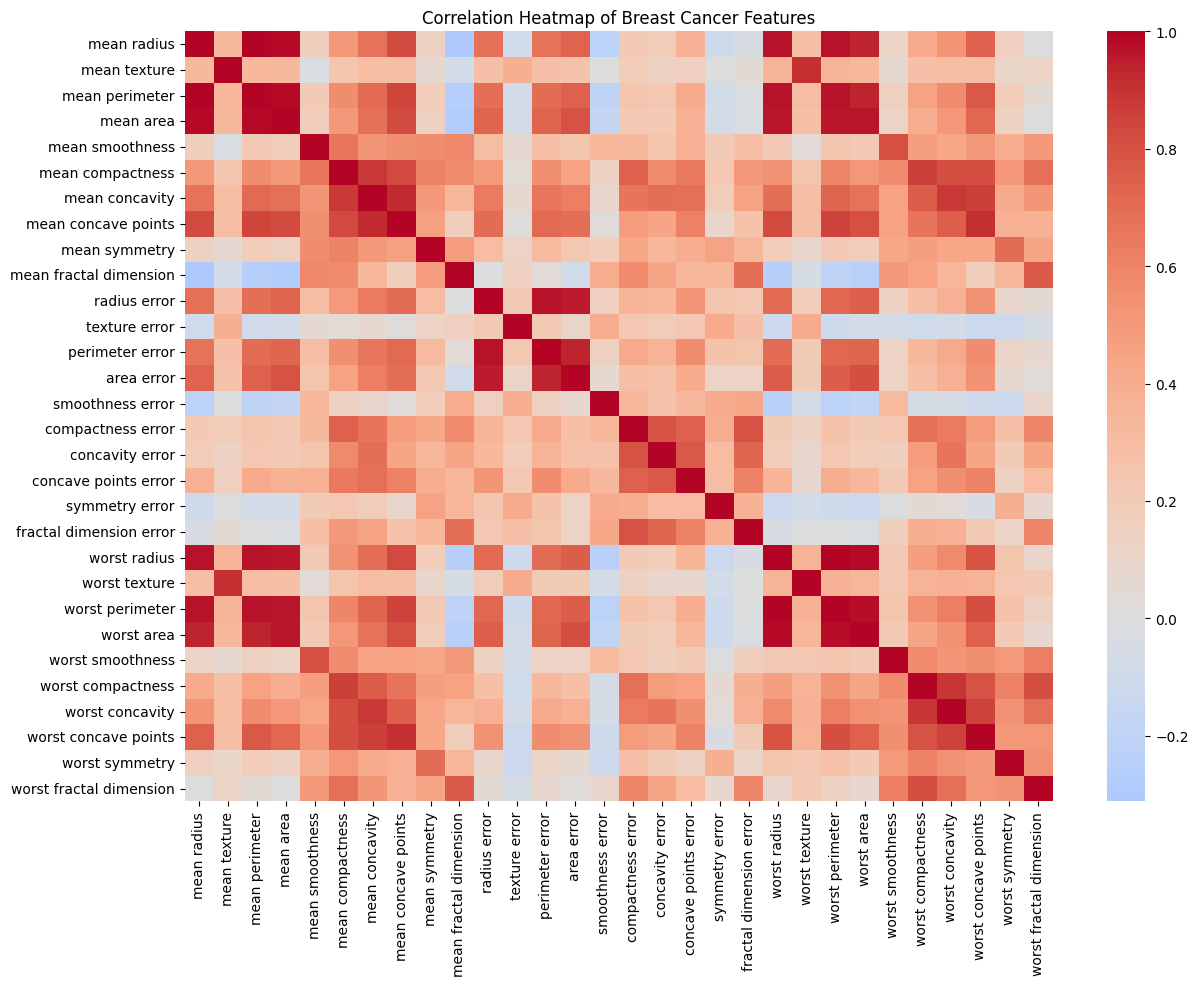

In [40]:
# Calculate correlations between numerical features
correlation_matrix = df.corr(numeric_only=True)

# Visualize the correlations
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Breast Cancer Features')
plt.show()

Data Preprocessing and Splitting

In [41]:
# Define Features and Target
X = df
y = maindata.target

In [42]:
# checking the shapeo f the features and target
print(X.shape)
print(y.shape)

(569, 30)
(569,)


Train-Test Split

In [43]:
from sklearn.model_selection import train_test_split

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(455, 30)
(114, 30)
(455,)
(114,)


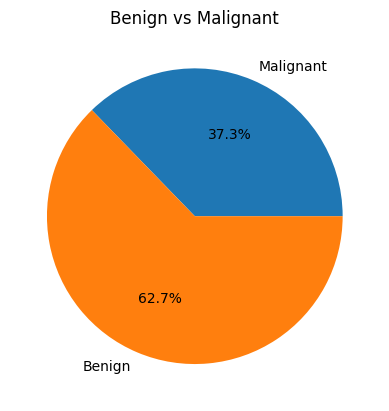

In [50]:
plt.pie(pd.Series(y).value_counts().sort_index(),
        labels=['Malignant', 'Benign'],
        autopct='%1.1f%%')
plt.title('Benign vs Malignant')
plt.show()

Feature Scaling

In [46]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [47]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(455, 30)
(114, 30)


Model Building

In [48]:
model = LogisticRegression(max_iter=10000, random_state=42)
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=10000, random_state=42)

Model Evaluation

Model Accuracy: 0.9824561403508771

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



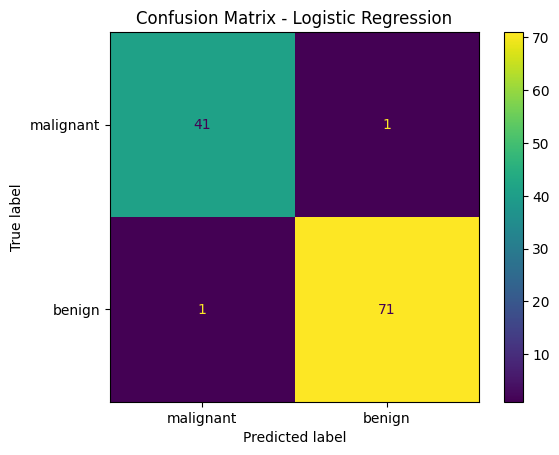

In [49]:
# Generate predictions
y_pred = model.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Model Accuracy:", accuracy)

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=maindata.target_names))

# Display confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=maindata.target_names
)
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

Conclusion
The logistic Regression model achieved high ccuracy in classifying breast tumors.
This project is just for study and cannot be used for real world practical detection of breat cancer by clinicians